In [232]:
import jax, jax.numpy as jnp, numpy as np
from hike import plot_map, plot_terrain, plot_map_terrain
import plotly.express as px

jax.config.update("jax_enable_x64", True)

# 0. The Landscape and Starting Point

In [223]:
def f(x, y):
    return (2 * (2 - x)**2 * jnp.exp(-x**2 - (y + 1)**2)
            - 15 * (x / 5 - x**3 - y**3) * jnp.exp(-x**2 - y**2)
            - jnp.exp(-(x + 1)**2 - y**2) / 3)

In [224]:
start = jnp.array([0.0,-2.5])

The height at the starting point:

In [225]:
f(start[0],start[1])

Array(0.39050688, dtype=float64)

The map (left) and the landscape (right). The red point is the starting point.

In [226]:
plot_map_terrain(f, points = [start])

# 1. The Compass 
*Introducing `jax.grad`*


To obtain the full gradient, it is convenient to write the terrain as a function of a single point p = (x, y) instead of two separate arguments. Otherwise we would need `jax.grad(f, argnums=(0, 1))` in every call. We call this function height

In [227]:
height = lambda p: f(p[0], p[1])
height(start)

Array(0.39050688, dtype=float64)

`jax.grad(height)` is a new function: the gradient of height. Evaluated at the starting point:

In [228]:
jax.grad(height)(start)

Array([-0.84851171,  0.80908705], dtype=float64)

The input can be a JAX or NumPy array, a tuple or a list, and the gradient comes back in the same structure. Since we will use it many times, we give the gradient function a short name: `grad_h`, our compass.

In [229]:
grad_h = jax.grad(height)
grad_h(start)

Array([-0.84851171,  0.80908705], dtype=float64)

#### Does the compass work?

We check it against central finite differences, (h(p + δe) − h(p − δe)) / 2δ, along x and along y:

In [231]:
delta = 1e-6
((height(start + delta * jnp.array([1.0,0.0])) - height(start - delta * jnp.array([1.0,0.0]))) / (2*delta),
(height(start + delta * jnp.array([0.0,1.0])) - height(start - delta * jnp.array([0.0,1.0]))) / (2*delta))

(Array(-0.84851171, dtype=float64), Array(0.80908705, dtype=float64))

**It is working!**

# 2. Going up with the "Steepest Ascent" Track
*Nested grads and Hessians* 

The simplest strategy: walk in the direction the compass shows, a distance α, until the height stops increasing along that line:

$\text{stop}_1 = \text{start} + \alpha^* \nabla h(\text{start})$ with $\alpha^*$ such that $[\frac{d  }{d \alpha}\text{height}( \text{start} + \alpha \nabla h(\text{start}))]_{\alpha^*}=0$

Then repeat from the new point.

#### The first segment

We write the height along the line as a function of the distance α, the starting point s and the direction d. Because α is the first argument, `jax.grad` differentiates with respect to α by default, with no `argnums` needed

In [108]:
def height_along(alpha, s, d):
    return height(s + alpha * d)

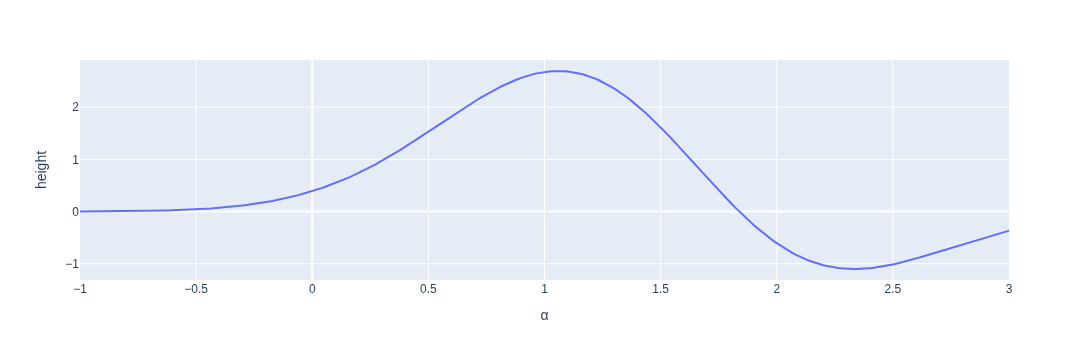

In [234]:
alphas = jnp.linspace(-1.0, 3.0, 300)
phi = lambda a: height_along(a, start, grad_h(start))
px.line(x=alphas, y=jax.vmap(phi)(alphas), labels={"x": "α", "y": "height"})

To find the maximum along the line we use Newton's method, which needs the first and second derivatives with respect to α. In JAX the second derivative is simply grad applied twice:

In [109]:
da_h = jax.grad(height_along)
da2_h = jax.grad(da_h)

Small trick kept for the moment: Plain Newton jumps to the top of the local parabola, which can be a minimum if the trail curves upward. Using |φ''| makes the parabola always open downward, so every step goes uphill.

In [110]:
def newton(x, df, d2f, tol=1e-10, maxiter=100):
    for _ in range(maxiter):
        step = df(x) / abs(d2f(x))
        x = x + step
        if abs(step) < tol:
            break
    return x

In [111]:
alpha_star = newton(0.0, lambda a: da_h(a, start, grad_h(start)), lambda a: da2_h(a, start, grad_h(start)))

In [123]:
stop1 = start + alpha_star * grad_h(start)

In [124]:
segment1 = start + jnp.linspace(0.0, alpha_star, 10)[:, None] * grad_h(start)

In [125]:
plot_map_terrain(f, points = [start], paths=[segment1])

For the second stop we do the same, starting Newton from α = 1. Starting from α = 0, Newton overshoots: the trail curves gently there, so its parabola predicts a top far beyond the first one.

In [137]:
alpha_star = newton(1.0, lambda a: da_h(a, stop1, grad_h(stop1)), lambda a: da2_h(a, stop1, grad_h(stop1)))

In [138]:
stop2 = stop1 + alpha_star * grad_h(stop1)

In [139]:
segment2 = stop1 + jnp.linspace(0.0, alpha_star, 10)[:, None] * grad_h(stop1)

In [142]:
plot_map_terrain(f, points = [start, stop1, stop2], paths=[segment1,segment2])

We continue in the same way until the compass no longer points anywhere (∇h ≈ 0), close to top = (−0.3593, −0.5519):

In [202]:
top = jnp.array([-0.3593, -0.55193])
grad_h(top)

Array([-0.00039866,  0.00011162], dtype=float64)

#### it is dark and we do not see anything at all. **Is it really the top?**

To find out, we look at how the ground curves around this point: the Hessian of h and its eigenvalues.

In [204]:
H_top = jax.hessian(height)(top)
eigvals, eigvecs = jnp.linalg.eigh(H_top)    # eigh: for symmetric matrices, sorted eigenvalues
eigvals

Array([-38.94489341, -16.98074091], dtype=float64)

Both eigenvalues are negative (≈ −38.9 and −17.0): the ground curves down in every direction, so this is a summit. At a mountain pass, one eigenvalue would be positive.

# 3. The Lowest Point on the Two-Summit Trail
*Constrained minimisation with Lagrange multipliers and the Jacobian*

Now let us imagine that the path is given and we wonder what is our nearest minimum to our `current_position`, such that we set our camp there.

In [237]:
center = jnp.array([0.85, 0.98])
radius = 1.0

def road(t):
    return center + radius * jnp.array([jnp.cos(t), jnp.sin(t)])

ts = jnp.linspace(0.0, 2 * jnp.pi, 200)
road_points = jax.vmap(road)(ts)

current_position = road(0.6)

plot_map_terrain(f, points={"current position":current_position}, paths={"ring road": road_points})

Mathematically, this is a minimisation with a constraint, solved with Lagrange multipliers. We describe the trail as the set of points where g(p) = 0:

In [187]:
g = lambda p: jnp.sum((p - center) ** 2) - radius ** 2

The gradient of g is perpendicular to the level curves, i.e g(p)= constant, in particular g(p)=0. This means that for all the points p in the path, ∇g(p) is perpendicular to the trail. On the other hand, the gradient of the height evaluated in the path is perpendicular to the path itself only in the extremum points. This means that in these points the two gradients are parallel to each other and the proportionality constant is the Lagrange multiplier, that we will call $l$.

Thus, we can set this problem as three scalar equations and three unknowns: 
- Equations: each component of l*∇g(p) = ∇height(p) and g(p)=0
- Unkowns:  z = x,y,l

Let us pack the three equations into a fucntion F(x,y,l) = F(z) = (l*∇g(p) - ∇height(p), g(p))

In [188]:
def F(z):
    p, l = z[:2], z[2]
    return jnp.append(grad_h(p) - l * jax.grad(g)(p), g(p))  

We perform a Newton's method to solve F(z) = 0. In this case since $F:R^3\to R^3$ the Newton step is `step = J^{-1}(z)F(z)`, which can be found with `jnp.linalg.solve(J(z), F(z))`

In [206]:
J = jax.jacobian(F)                 

z = jnp.append(current_position, 0.0)          # start with λ = 0

for _ in range(20):
    z = z - jnp.linalg.solve(J(z), F(z))

z, height(z[:2])

(Array([ 1.53976163,  1.70403653, -1.03656454], dtype=float64),
 Array(0.63671947, dtype=float64))

In [239]:
plot_map_terrain(f, points={"current position":current_position, "nearest minimum":z[:2]}, paths={"ring road": road_points})

In [191]:
import plotly.graph_objects as go

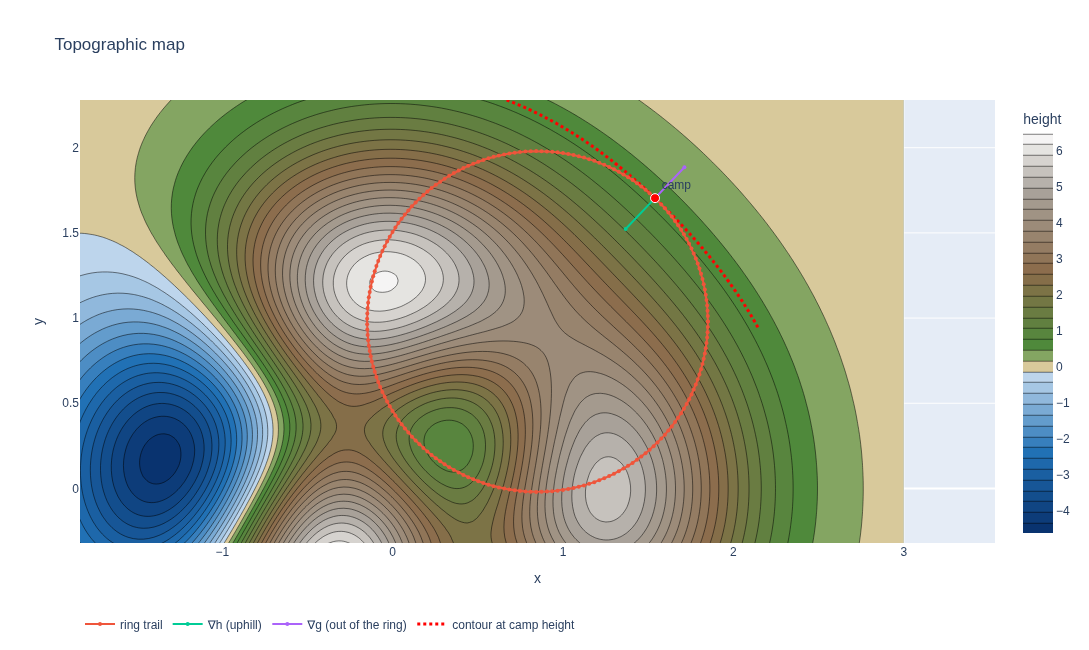

In [192]:
camp = z[:2]
road_points = jax.vmap(road)(jnp.linspace(0, 2 * jnp.pi, 200))
u = grad_h(camp) / jnp.linalg.norm(grad_h(camp))              # uphill, unit length
v = jax.grad(g)(camp) / jnp.linalg.norm(jax.grad(g)(camp))     # out of the ring, unit length

fig = plot_map(f, points={"camp": camp}, show=False,
               paths={"ring trail": road_points,
                      "∇h (uphill)": jnp.stack([camp, camp + 0.25 * u]),
                      "∇g (out of the ring)": jnp.stack([camp, camp + 0.25 * v])})

# zoom window around the ring, whatever its radius
pad = 0.3
x_lim = [float(center[0] - radius - pad), float(center[0] + radius + pad)]
y_lim = [float(center[1] - radius - pad), float(center[1] + radius + pad)]

# the single contour line at the camp's height
xs = jnp.linspace(*x_lim, 200); ys = jnp.linspace(*y_lim, 200)
Zc = jax.vmap(jax.vmap(f))(*jnp.meshgrid(xs, ys))
fig.add_trace(go.Contour(x=xs, y=ys, z=Zc, showscale=False, name="contour at camp height",
                         contours=dict(start=float(height(camp)), end=float(height(camp)), coloring="none"),
                         line=dict(color="red", width=3, dash="dot")))

fig.update_xaxes(range=x_lim); fig.update_yaxes(range=y_lim)
fig.update_layout(legend=dict(orientation="h", y=-0.15))
fig.show()